# Most frequent value means mode.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("00 train.csv", usecols = ['GarageQual','FireplaceQu','SalePrice'])

In [3]:
df.sample(5)

,FireplaceQu,GarageQual,SalePrice
1001,NaN,Fa,86000
1451,Gd,TA,287090
850,NaN,TA,131500
825,Gd,TA,385000
1040,TA,TA,155000


In [4]:
df.isnull().sum()

FireplaceQu    690
GarageQual      81
SalePrice        0
dtype: int64

In [5]:
# Percentage of missing values in each columns

(df.isnull().sum()/len(df))*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

<AxesSubplot: xlabel='count', ylabel='GarageQual'>

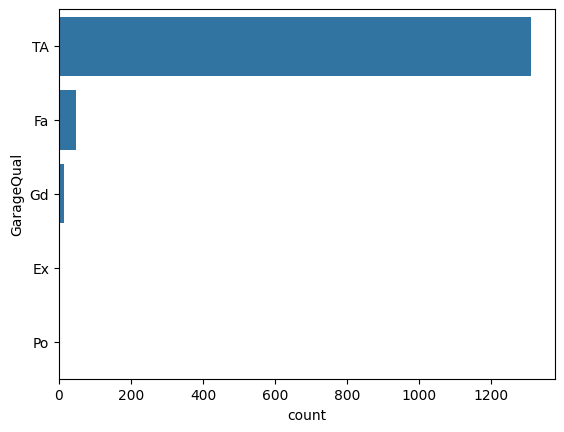

In [7]:
sns.countplot(df['GarageQual'])

<AxesSubplot: >

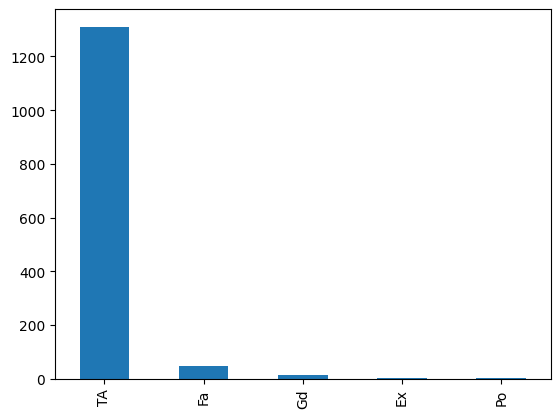

In [8]:
df['GarageQual'].value_counts().plot(kind = 'bar')

In [9]:
df['GarageQual'].value_counts()

TA    1311
Fa      48
Gd      14
Ex       3
Po       3
Name: GarageQual, dtype: int64

In [10]:
df['GarageQual'].mode()

0    TA
Name: GarageQual, dtype: object

In [45]:
df['Garage_mode'] = df['GarageQual'].fillna('TA')

In [46]:
df['Garage_mode'].value_counts()

TA    1392
Fa      48
Gd      14
Ex       3
Po       3
Name: Garage_mode, dtype: int64

In [47]:
mode_fire = df['FireplaceQu'].mode()[0]

In [48]:
mode_fire

'Gd'

In [49]:
df['FireplaceQu'] = df['FireplaceQu'].fillna(mode_fire)

In [50]:
df.isnull().sum()

FireplaceQu     0
GarageQual     81
SalePrice       0
Garage_mode     0
dtype: int64

# Using sklearn.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [18]:
x = df.iloc[:, 0:2]
y = df.SalePrice

x

,FireplaceQu,GarageQual
0,Gd,TA
1,TA,TA
2,TA,TA
3,Gd,TA
4,TA,TA
...,...,...
1455,TA,TA
1456,TA,TA
1457,Gd,TA
1458,Gd,TA


In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y , test_size = 0.2)

In [20]:
si = SimpleImputer(strategy = 'most_frequent')

In [21]:
x_train_trans = si.fit_transform(x_train)
x_test_trans = si.transform(x_test)

In [22]:
si.statistics_

array(['Gd', 'TA'], dtype=object)

# Imputing 'Missing' word in place of null values.

In [23]:
x_train2, x_test2, y_train2, y_test2 = train_test_split(x, y , test_size = 0.2)

In [24]:
si2 = SimpleImputer(strategy = 'constant', fill_value = 'Missing')

In [25]:
x_train2 = si2.fit_transform(x_train2)
x_test2 = si2.transform(x_test2)

In [26]:
si2.statistics_

array(['Missing', 'Missing'], dtype=object)

In [29]:
df2 = pd.DataFrame(x_train2, columns = x.columns)

In [30]:
df2.sample(10)

,FireplaceQu,GarageQual
699,TA,TA
868,TA,TA
582,Gd,Missing
814,TA,TA
183,Gd,Missing
263,TA,TA
317,Gd,TA
309,Gd,TA
90,TA,TA
987,Gd,TA


In [37]:
df2[df2['GarageQual'] == 'Missing']

,FireplaceQu,GarageQual
0,TA,Missing
2,Gd,Missing
12,TA,Missing
28,Gd,Missing
58,Gd,Missing
...,...,...
1123,Gd,Missing
1131,Gd,Missing
1134,Gd,Missing
1160,Gd,Missing


In [38]:
df2[df2['GarageQual'] == 'Missing'].count()

# We want count of 'Missing' word present in eachh column. Here 'FireplaceQu' has 0 'Missing' word
# Even then it shows 71. Let's see bolow code to solve this error.

FireplaceQu    71
GarageQual     71
dtype: int64

In [43]:
df2[df2 == 'Missing']

,FireplaceQu,GarageQual
0,NaN,Missing
1,NaN,NaN
2,NaN,Missing
3,NaN,NaN
4,NaN,NaN
...,...,...
1163,NaN,NaN
1164,NaN,NaN
1165,NaN,NaN
1166,NaN,Missing


In [40]:
df2[df2 == 'Missing'].count()

FireplaceQu     0
GarageQual     71
dtype: int64